# Comparación unconstrained vs. constrained vs. constrained_rank

Notebook aparte de `training.ipynb` (no lo modifica). Reúne métricas de comparación entre
los tres modelos (`unconstrained`: sin penalización; `constrained`: producto punto entre cabezas;
`constrained_rank`: producto punto + anti-colapso por cabeza), todos los pares:

1. **CKA entre la salida del MLP del último bloque**, comparando los modelos completos par a par.
2. **CKA entre cada cabeza de atención**, bloque a bloque, comparando las 4 cabezas de
   un modelo contra las 4 de otro — una cuadrícula de calor por bloque y por par de modelos.

Ambas usan [CKA lineal (Kornblith et al., 2019)](https://arxiv.org/abs/1905.00414), ya
implementada en `modules/cka.py`.

**Nota metodológica:** CKA compara la geometría de las representaciones salvo rotación y
escala isotrópica. Dos modelos entrenados por separado (distinta inicialización, sin
ninguna restricción de simetría entre ellos) no tienen por qué alinear sus neuronas ni sus
cabezas de la misma forma — un valor bajo entre, por ejemplo, dos cabezas de modelos distintos no
implica que una de las dos "funcione mal"; es una limitación conocida de comparar redes
independientes con esta métrica. Vale la pena tenerlo en cuenta al interpretar los
números de abajo.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# el notebook vive en notebooks/<carpeta>/, dos niveles bajo la raíz del proyecto
project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.model import ViTForClassfication
from modules.cka import linear_cka
from modules.figures import save_fig

torch.manual_seed(0)
device = torch.device("cpu")  # el modelo es diminuto (hidden_size=48) — no hace falta GPU/MPS aquí


## 1. Cargar los tres modelos

`experimentation/experiments/<nombre>/` guarda pesos + `config.json` + `metrics.json` juntos
(vía `save_experiment`). Uso los tres entrenados sobre AwA2 (mismo config, misma seed de datos).

In [2]:
EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"

MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
}
PAIRS = [("unconstrained", "constrained"), ("unconstrained", "constrained_rank"), ("constrained", "constrained_rank")]

OUTPUT_DIR = EXPERIMENTS_DIR / "17082026_comparing_models_cka"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

configs = {k: json.loads((EXPERIMENTS_DIR / name / "config.json").read_text()) for k, name in MODELS.items()}
config = configs["unconstrained"]
assert all(c == config for c in configs.values()), (
    "Los checkpoints tienen arquitecturas distintas — no son comparables con CKA. "
    "Revisa qué experimentos estás cargando."
)

models = {}
for k, name in MODELS.items():
    m = ViTForClassfication(config).to(device)
    m.load_state_dict(torch.load(EXPERIMENTS_DIR / name / "model_final.pt", map_location=device))
    models[k] = m.eval()

print("Modelos cargados:", list(models), "| num_hidden_layers =", config["num_hidden_layers"],
      "| num_attention_heads =", config["num_attention_heads"])

Modelos cargados: ['unconstrained', 'constrained', 'constrained_rank'] | num_hidden_layers = 4 | num_attention_heads = 4


## 2. Cargar un batch de ejemplos

`AwA2Dataset` usa el cache local ya construido en `data/awa2/` (no vuelve a descargar nada). 15 ejemplos,
semilla fija para que la comparación sea reproducible.

In [3]:
from modules.datasets import AwA2Dataset

_dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, _testloader, _classes = _dataset.get_loaders(batch_size=256)

N_SAMPLES = 15
indices = torch.randperm(len(_dataset.testset))[:N_SAMPLES].tolist()
batch, labels = _dataset.get_samples_from_indices(indices, device=device, set="test")

print("Batch:", batch.shape, "| clases en el batch:",
      [_dataset.classes[l] for l in labels.tolist()])

Batch: torch.Size([15, 3, 32, 32]) | clases en el batch: ['horse', 'elephant', 'collie', 'bat', 'fox', 'squirrel', 'squirrel', 'moose', 'antelope', 'seal', 'leopard', 'fox', 'polar bear', 'rat', 'dolphin']


## 3. CKA en la última capa del MLP

Un forward hook sobre `blocks[-1].mlp` de cada modelo, con el mismo batch, y CKA lineal
entre las dos activaciones (aplanando batch × posiciones de secuencia como los "ejemplos"
de CKA, igual que en Kornblith et al.).

In [4]:
mlp_activations = {}

def _make_mlp_hook(name):
    def hook(module, inputs, output):
        mlp_activations[name] = output.detach()
    return hook

handles = [m.encoder.blocks[-1].mlp.register_forward_hook(_make_mlp_hook(k)) for k, m in models.items()]

with torch.no_grad():
    for m in models.values():
        m(batch, output_attentions=False)

for h in handles:
    h.remove()

acts = {k: a.reshape(-1, config["hidden_size"]) for k, a in mlp_activations.items()}
cka_mlp = {}
for a, b in PAIRS:
    cka_mlp[(a, b)] = float(linear_cka(acts[a], acts[b]))
    print(f"CKA(MLP último bloque, {a} vs. {b}) = {cka_mlp[(a, b)]:.4f}")

CKA(MLP último bloque, unconstrained vs. constrained) = 0.0424
CKA(MLP último bloque, unconstrained vs. constrained_rank) = 0.2464
CKA(MLP último bloque, constrained vs. constrained_rank) = 0.0453


## 4. CKA entre cabezas de atención, bloque a bloque

Un forward hook por cada `AttentionHead` (hay `num_attention_heads` por bloque, en los
4 bloques, en cada modelo) que captura su `attention_output` — la salida real de la
cabeza `softmax(QKᵀ)·V`, no los pesos. Con el mismo batch de arriba, para cada bloque
armo la matriz 4×4 de CKA entre las 4 cabezas del modelo interpretable (filas) y las
4 del no interpretable (columnas).

In [5]:
head_outputs = {k: {} for k in models}

def _make_head_hook(store, block_idx, head_idx):
    def hook(module, inputs, output):
        store[(block_idx, head_idx)] = output[0].detach()
    return hook

handles = []
for k, m in models.items():
    for block_idx, block in enumerate(m.encoder.blocks):
        for head_idx, head in enumerate(block.attention.heads):
            handles.append(head.register_forward_hook(_make_head_hook(head_outputs[k], block_idx, head_idx)))

with torch.no_grad():
    for m in models.values():
        m(batch, output_attentions=False)

for h in handles:
    h.remove()

num_blocks = config["num_hidden_layers"]
num_heads = config["num_attention_heads"]
head_size = config["hidden_size"] // num_heads

cka_matrices = {}
for a, b in PAIRS:
    mat = torch.zeros(num_blocks, num_heads, num_heads)
    for blk in range(num_blocks):
        for i in range(num_heads):      # cabeza del modelo `a` (filas)
            x_i = head_outputs[a][(blk, i)].reshape(-1, head_size)
            for j in range(num_heads):  # cabeza del modelo `b` (columnas)
                x_j = head_outputs[b][(blk, j)].reshape(-1, head_size)
                mat[blk, i, j] = linear_cka(x_i, x_j)
    cka_matrices[(a, b)] = mat.numpy()
    print(f"{a} vs. {b}: CKA medio por bloque = {np.round(cka_matrices[(a, b)].mean(axis=(1, 2)), 3)}")

unconstrained vs. constrained: CKA medio por bloque = [0.515 0.437 0.339 0.307]
unconstrained vs. constrained_rank: CKA medio por bloque = [0.523 0.528 0.395 0.387]
constrained vs. constrained_rank: CKA medio por bloque = [0.475 0.527 0.384 0.365]


## 5. Visualización — cuadrícula de calor por bloque

Paleta secuencial (un solo hue, claro→oscuro) del skill de dataviz — es el encoding
correcto para "comparar magnitud en una cuadrícula". Valor de CKA anotado en cada celda,
mismo estilo que la matriz de confusión que ya usan en `training.ipynb`.

guardado: experimentation/experiments/17082026_comparing_models_cka/cka_heads_heatmap_vit-15-AwA2_unconstrained_constrained_constrained_rank.png


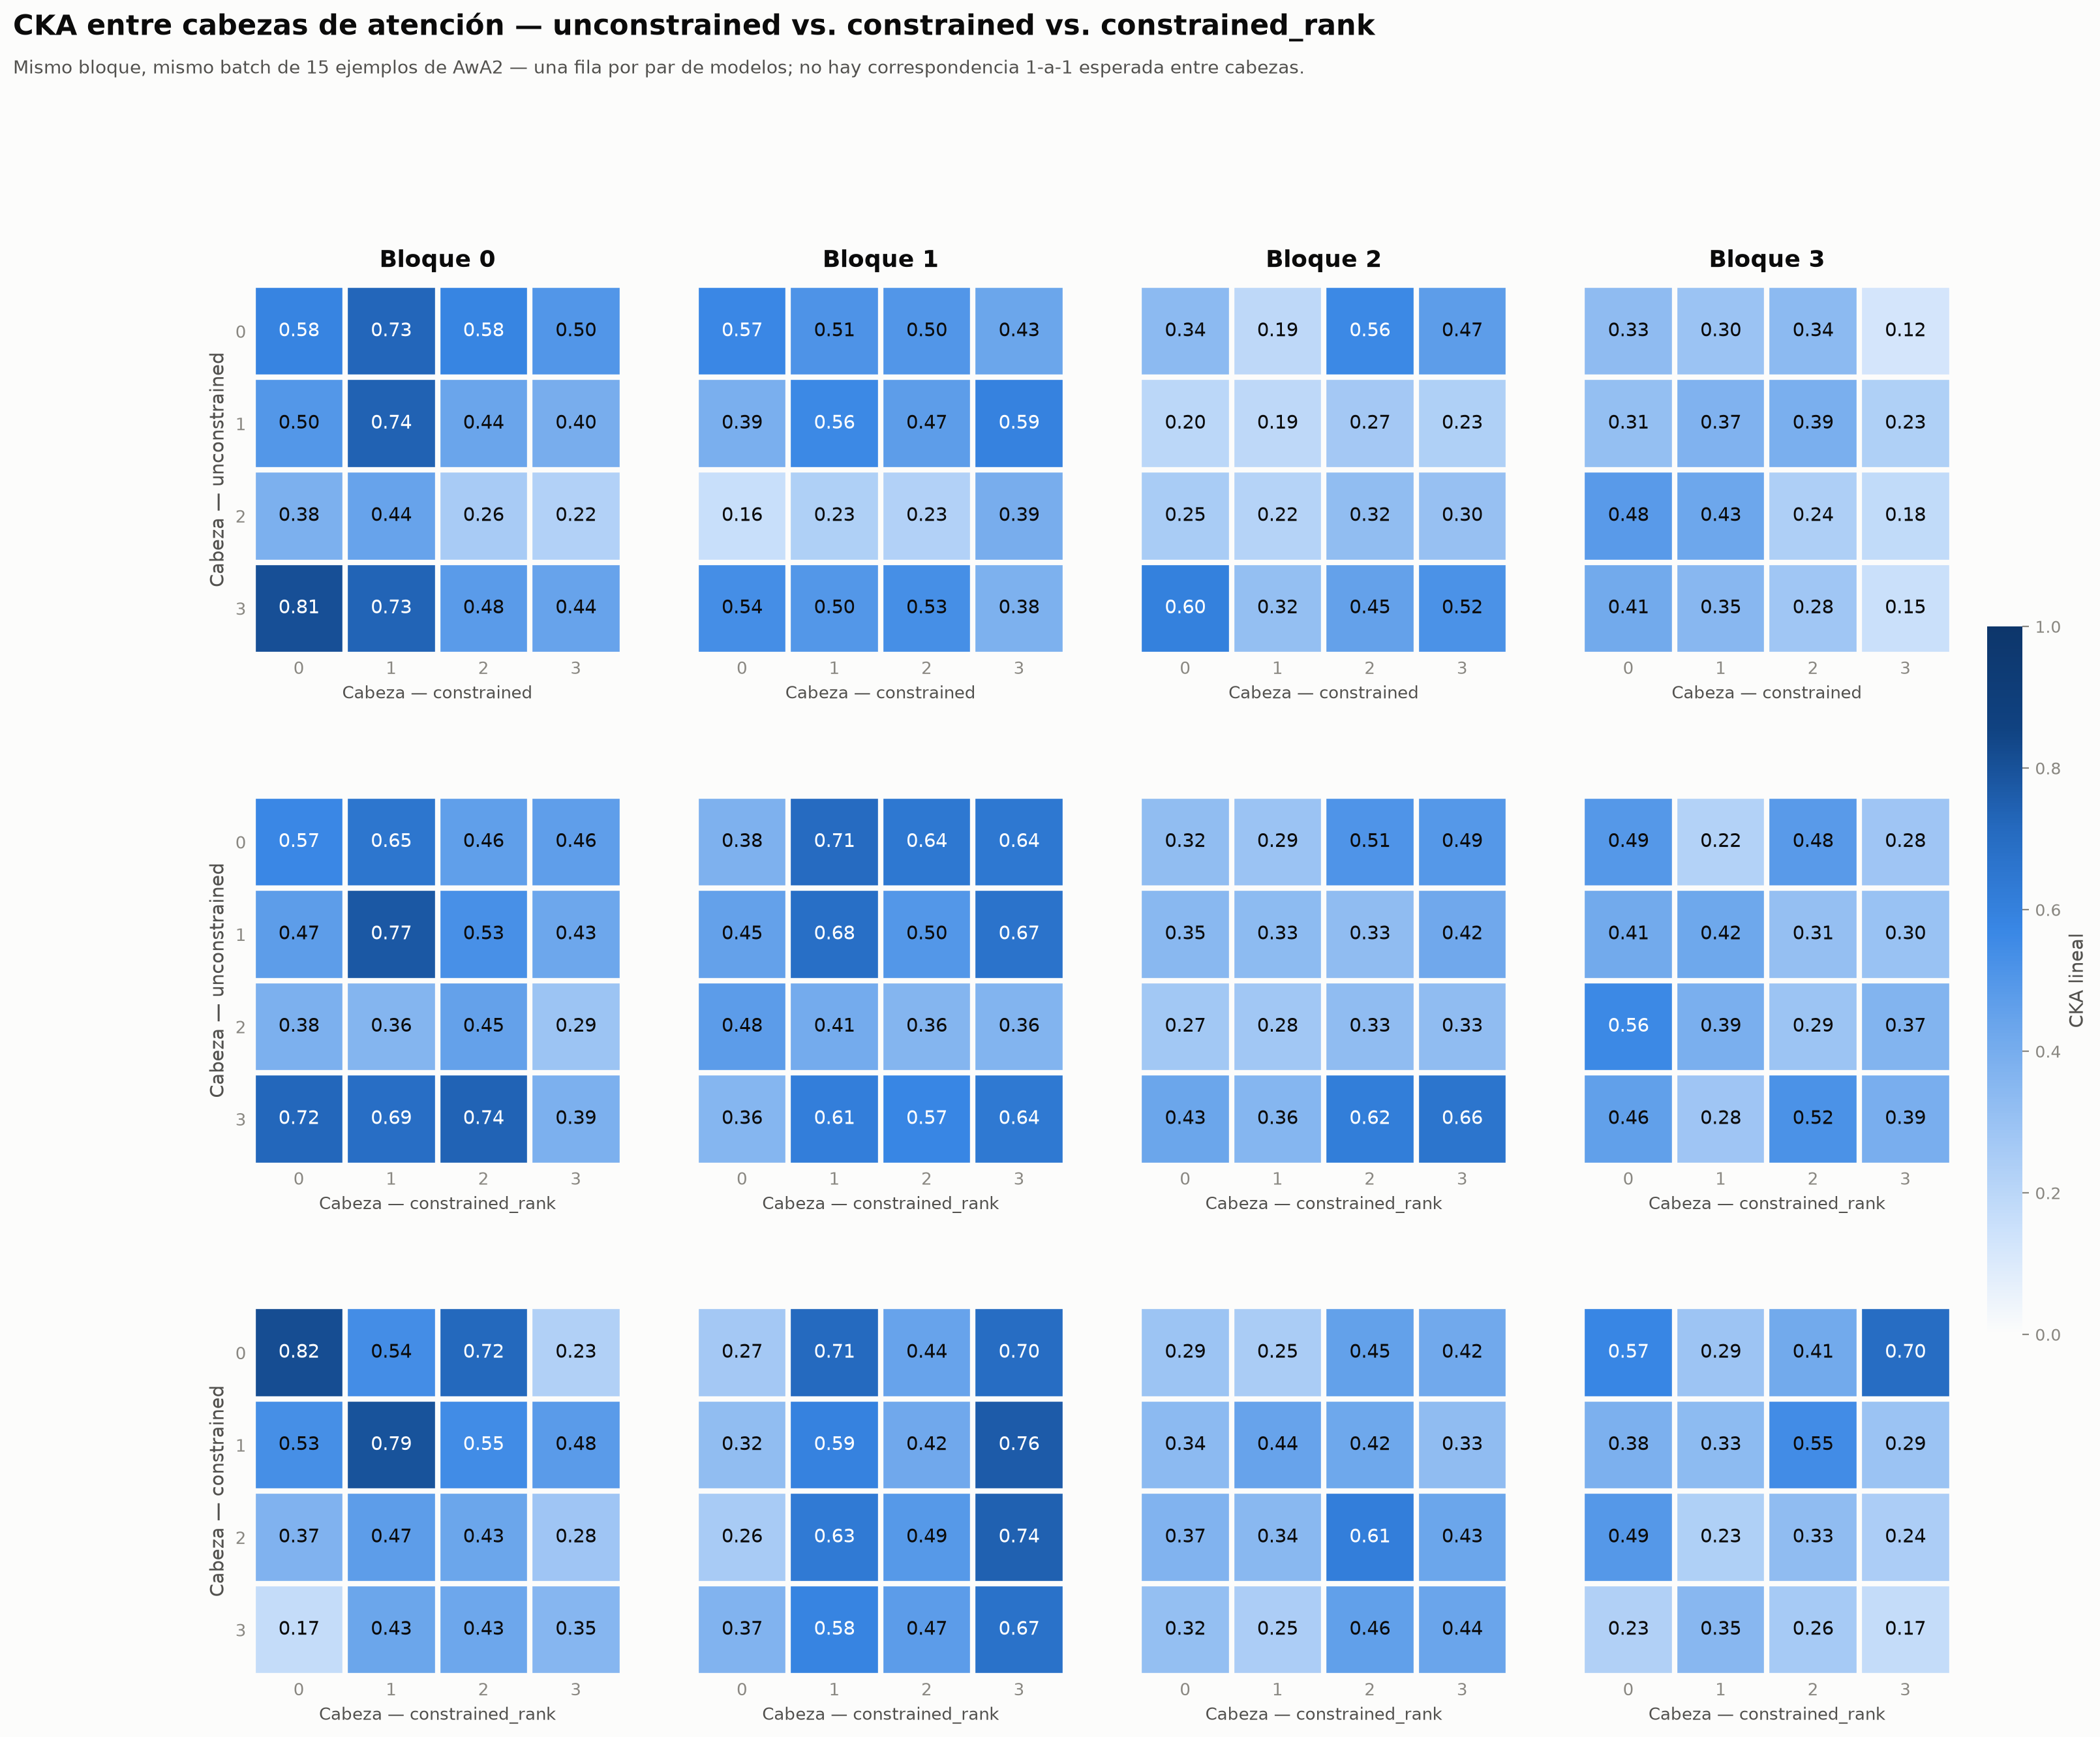

In [6]:
SURFACE, INK, INK_SEC, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]

# Rampa secuencial validada (references/palette.md del skill de dataviz), azul claro->oscuro
seq_steps = ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281", "#0d366b"]
cmap = mcolors.LinearSegmentedColormap.from_list("seq_blue", seq_steps)

fig, axes = plt.subplots(len(PAIRS), num_blocks, figsize=(4 * num_blocks + 1.5, 4.8 * len(PAIRS)), dpi=200)
fig.patch.set_facecolor(SURFACE)

im = None
for r, (a, b) in enumerate(PAIRS):
    for blk in range(num_blocks):
        ax = axes[r, blk]
        ax.set_facecolor(SURFACE)
        mat = cka_matrices[(a, b)][blk]
        im = ax.imshow(mat, cmap=cmap, vmin=0.0, vmax=1.0)

        for i in range(num_heads):
            for j in range(num_heads):
                val = mat[i, j]
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=10.5,
                        color="white" if val > 0.55 else INK)

        ax.set_xticks(range(num_heads))
        ax.set_yticks(range(num_heads))
        ax.set_xticklabels([f"{k}" for k in range(num_heads)], color=INK_MUTED, fontsize=9.5)
        if blk == 0:
            ax.set_yticklabels([f"{k}" for k in range(num_heads)], color=INK_MUTED, fontsize=9.5)
            ax.set_ylabel(f"Cabeza — {a}", color=INK_SEC, fontsize=10.5)
        else:
            ax.set_yticklabels([])
        ax.set_xlabel(f"Cabeza — {b}", color=INK_SEC, fontsize=9.5)
        if r == 0:
            ax.set_title(f"Bloque {blk}", color=INK, fontsize=13, fontweight="bold", pad=10)

        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xticks(np.arange(-0.5, num_heads, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, num_heads, 1), minor=True)
        ax.grid(which="minor", color=SURFACE, linewidth=3)
        ax.tick_params(which="minor", length=0)
        ax.tick_params(which="major", length=0)

cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, shrink=0.85)
cbar.set_label("CKA lineal", color=INK_SEC, fontsize=10.5)
cbar.ax.tick_params(colors=INK_MUTED, labelsize=9)
cbar.outline.set_visible(False)

fig.suptitle("CKA entre cabezas de atención — unconstrained vs. constrained vs. constrained_rank",
             color=INK, fontsize=15.5, fontweight="bold", x=0.02, ha="left", y=1.01)
fig.text(0.02, 0.985,
         f"Mismo bloque, mismo batch de {N_SAMPLES} ejemplos de AwA2 — una fila por par de modelos; "
         "no hay correspondencia 1-a-1 esperada entre cabezas.",
         color=INK_SEC, fontsize=10, ha="left", va="top")

save_fig(fig, "cka_heads_heatmap", OUTPUT_DIR, tag="vit-15-AwA2_unconstrained_constrained_constrained_rank",
         project_root=project_root)
plt.show()

## 6. Similitud entre cabezas DENTRO de cada modelo

Las secciones anteriores comparan cabezas de modelos distintos. Aquí se mide qué tan parecidas son
entre sí las 4 cabezas de un mismo modelo, a tres niveles:

- **Mapa de atención del CLS** (coseno): el objeto sobre el que actúa la penalización de producto punto.
- **Salida de la cabeza, token CLS** (CKA lineal): lo que el probing y el clasificador leen.
- **Salida de la cabeza, todos los tokens** (CKA lineal).

Si la penalización solo separa *dónde mira* cada cabeza pero no *qué transporta*, el coseno de atención
baja y el CKA de salidas no. 1000 imágenes de test, semilla fija.

coseno atención CLS                                CKA salida CLS  \
modelo         constrained constrained_rank unconstrained    constrained   
bloque                                                                     
1                    0.345            0.283         0.371          0.374   
2                    0.386            0.313         0.213          0.172   
3                    0.256            0.206         0.318          0.102   
4                    0.009            0.007         0.185          0.055   

                                      CKA salida (todos los tokens)  \
modelo constrained_rank unconstrained                   constrained   
bloque                                                                
1                 0.151         0.351                         0.509   
2                 0.180         0.088                         0.380   
3                 0.082         0.193                         0.256   
4                 0.046         0.141                         0.060   

                                       
modelo constrained_rank unconstrained  
bloque                                 
1                 0.269         0.426  
2                 0.396         0.370  
3                 0.362         0.289  
4                 0.060         0.145

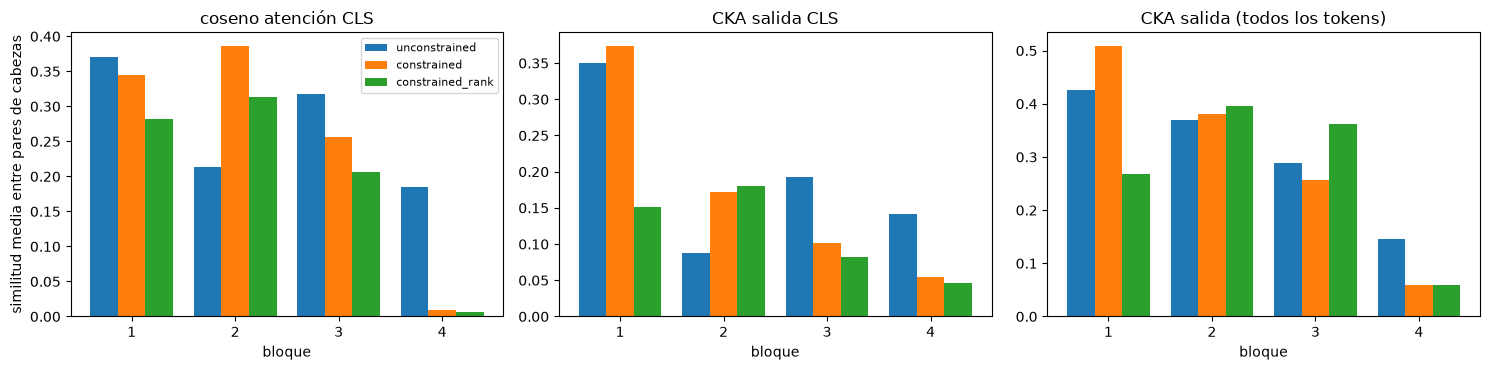

In [7]:
import pandas as pd

N_EVAL = 1000
_g = torch.Generator().manual_seed(0)
eval_idx = torch.randperm(len(_dataset.testset), generator=_g)[:N_EVAL].tolist()
eval_batch, _ = _dataset.get_samples_from_indices(eval_idx, device=device, set="test")


def collect_heads(model):
    outs, probs, hooks = {}, {}, []
    for b, block in enumerate(model.encoder.blocks):
        for h, head in enumerate(block.attention.heads):
            def hook(_m, _i, out, b=b, h=h):
                outs[(b, h)], probs[(b, h)] = out[0].detach(), out[1].detach()
            hooks.append(head.register_forward_hook(hook))
    with torch.no_grad():
        model(eval_batch, output_attentions=False)
    for hk in hooks:
        hk.remove()
    return outs, probs


head_pairs = [(i, j) for i in range(num_heads) for j in range(i + 1, num_heads)]
rows = []
for key, m in models.items():
    outs, probs = collect_heads(m)
    for b in range(num_blocks):
        cka_all, cka_cls, cos_att = [], [], []
        for i, j in head_pairs:
            cka_all.append(float(linear_cka(outs[(b, i)].reshape(-1, head_size), outs[(b, j)].reshape(-1, head_size))))
            cka_cls.append(float(linear_cka(outs[(b, i)][:, 0], outs[(b, j)][:, 0])))
            a_i, a_j = probs[(b, i)][:, 0, 1:], probs[(b, j)][:, 0, 1:]
            cos_att.append(float(torch.nn.functional.cosine_similarity(a_i, a_j, dim=-1).mean()))
        rows.append({"modelo": key, "bloque": b + 1,
                     "coseno atención CLS": np.mean(cos_att),
                     "CKA salida CLS": np.mean(cka_cls),
                     "CKA salida (todos los tokens)": np.mean(cka_all)})
within = pd.DataFrame(rows)
within.to_csv(OUTPUT_DIR / "within_model_head_similarity.csv", index=False)
display(within.pivot(index="bloque", columns="modelo",
        values=["coseno atención CLS", "CKA salida CLS", "CKA salida (todos los tokens)"]).round(3))

metrics = ["coseno atención CLS", "CKA salida CLS", "CKA salida (todos los tokens)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
w = 0.8 / len(models)
for ax, metric in zip(axes, metrics):
    for k, key in enumerate(models):
        sub = within[within["modelo"] == key]
        ax.bar(sub["bloque"] + (k - (len(models) - 1) / 2) * w, sub[metric], width=w, label=key)
    ax.set_title(metric); ax.set_xlabel("bloque"); ax.set_xticks(range(1, num_blocks + 1))
axes[0].set_ylabel("similitud media entre pares de cabezas"); axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "within_model_head_similarity.png", dpi=150, bbox_inches="tight")
plt.show()

## Resumen

- **CKA(MLP, último bloque)**: un solo número (celda de arriba) — cobra más sentido
  comparado contra otras corridas o contra la CKA de las cabezas, no tanto como valor
  absoluto aislado.
- **CKA por cabeza, bloque a bloque**: la cuadrícula de arriba, guardada también como
  `cka_heads_heatmap.png` junto a este notebook para usar directo en el póster.